# JOJA — Turn Ordinary Data Into Insights

## Contexte et objectif

Ce notebook présente une analyse exploratoire de données (EDA) d'un site de livraison de courses en ligne, à partir d'un dataset réel de plus de 3 millions de commandes et 200 000 utilisateurs. 

L'objectif pour nous est d'identifier des tendances et comportements d'achat exploitables afin de proposer des actions concrètes pour améliorer le business.

## Structure du notebook

1. **Rayon / Département** : diversité de l'assortiment et son lien avec le volume de commandes
2. **Produits** : bestsellers, comportement d'achat au niveau produit
3. **Evolution du comportement d'achat** : fidélité, taux de réachat, segmentation client
4. **Temporalité** : quand les clients commandent, et variations selon le profil client
5. **Machine Learning** : prédiction du réachat produit à partir de l'historique client

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import pearsonr

from src.data_loader import get_data, load_raw_data
from src.features import enrich_dataframe

sns.set_theme(style="whitegrid", font_scale=1)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "#fafafa",
    "figure.facecolor": "white",
})

COLORS = {
    "occasionnel": "#a8bfc1",
    "typique":     "#4290ba",
    "fidèle":      "#1b3a4b",
    "accent":      "#3cc494",
    "grey":        "#6b7280",
}
PAL_SEGMENTS = [COLORS["occasionnel"], COLORS["typique"], COLORS["fidèle"]]

data = get_data(raw_dir="data/raw", processed_path="data/processed/merged_orders.parquet")
data = enrich_dataframe(data)

raw = load_raw_data(raw_dir="data/raw")
orders = raw["orders"]
order_products = raw["order_products"]
products = raw["products"]
aisles = raw["aisles"]
departments = raw["departments"]

print(f"Dataset: {data.shape[0]:,} lignes, {data.shape[1]} colonnes")

Chargement depuis le cache .parquet
Dataset: 10,737,546 lignes, 22 colonnes


## Préparation des données

Le projet s'appuie sur 5 tables sources (`orders`, `order_products`, `products`, `aisles`, `departments`), fusionnées en une seule table de travail (`data`) via `src/data_loader.py`. Le détail complet de l'exploration et du nettoyage est disponible dans `notebooks/01_data_loading_cleaning.ipynb`.
Cette section en résume les étapes et décisions clés.

### Nettoyage effectué

- **1 ligne corrompue** supprimée dans `order_products` (valeurs manquantes sur plusieurs colonnes simultanément, sur 10 737 547 lignes)
- **Aucun doublon** détecté dans les 5 tables
- Les valeurs manquantes de `days_since_prior_order` (206 209 sur `orders`) sont conservées : elles correspondent systématiquement à la première commande de chaque utilisateur (vérifié 100% de correspondance)

In [9]:
print(f"Table data : {data.shape[0]:,} lignes, {data.shape[1]} colonnes")
print(f"Valeurs manquantes restantes (hors days_since_prior_order) :")
print(data.drop(columns="days_since_prior_order").isnull().sum().sum())

Table data : 10,737,546 lignes, 22 colonnes
Valeurs manquantes restantes (hors days_since_prior_order) :
0


### Couverture des données

Le fichier `order_products.csv` ne couvre qu'un sous-ensemble des commandes de `orders.csv` : environ 1 064 689 commandes sur 3,4 millions, mais 92,1% des utilisateurs (189 980 sur 206 209) restent représentés avec une partie de leur historique.
Cette limitation, documentée en détail dans le brouillon d'exploration, n'invalide pas la représentativité des analyses menées sur `data`.

### Segmentation client

Les clients sont répartis en 3 segments selon leur nombre total de commandes, basé sur les quartiles observés (et non un seuil arbitraire) :

| Segment | Nombre de commandes | % des utilisateurs |
|---|---|---|
| Occasionnel | ≤ 6 | 25% |
| Typique | 7 à 20 | 50% |
| Fidèle | > 20 | 25% |

Cette segmentation est calculée automatiquement via `add_customer_segment()` dans `src/features.py`, et appliquée à `data` par `enrich_dataframe()`.

# I. Rayon / Département

**Objectif** : Comprendre comment les produits sont répartis entre rayons et départements, et si cette répartition (diversité, volume de commandes) influence les habitudes d'achat des clients.

**Questions à traiter** :

1. Combien de produits uniques existent par rayon/département ?
2. Y a-t-il un lien entre la diversité de produits d'un rayon et son volume de commandes ?
3. Dans un panier, combien de produits de différents départements/rayons peut-on trouver, et cette diversité diffère-t-elle selon le segment client ?

**Impact business attendu** : Déterminer si l'organisation du catalogue 
en ligne influence les commandes, afin d'identifier les rayons à mettre 
en avant ou à réévaluer en termes d'assortiment.

### Note méthodologique : les catégories "missing" et "other"

Deux catégories techniques ont été identifiées parmi les rayons et départements : "missing" et "other", qui ne correspondent pas à de vrais rayons physiques du site, mais regroupent des produits dont la catégorisation d'origine n'était pas renseignée dans les données sources.

**Vérification effectuée :** 
Un vrai département contient plusieurs rayons distincts ; "missing" et "other" n'en contiennent chacun qu'un seul, une structure anormale confirmée par un comptage systématique. 
Les produits de ces catégories ont par ailleurs des noms parfaitement renseignés (ex : "Organic Honeycrisp Apples", "Rescue Remedy"), écartant un problème de fiabilité sur les produits eux-mêmes.

**Décision :** 
Ces catégories représentent un poids non négligeable du catalogue (~2,5% et ~1,1% des produits référencés) mais un poids marginal des commandes réelles (0,21% et 0,11% des lignes de `data`, seulement 10 utilisateurs concernés exclusivement sur ~206 000). Elles sont donc **conservées** dans l'analyse (aucune donnée de vente n'est supprimée), mais **signalées visuellement** dans les graphiques concernés plutôt que mélangées aux vrais rayons.

## Question 1 : Combien de produits uniques existent par rayon/département ?

Pour répondre à cette question, on compte le nombre de produits uniques 
(`.nunique()`) par rayon et par département, à partir du catalogue `products` (et non de `data`, qui ne reflète que les produits effectivement commandés, pas le catalogue complet).

In [10]:
products_full = products.merge(aisles, on="aisle_id", how="left")
products_full = products_full.merge(departments, on="department_id", how="left")

products_per_aisle = products_full.groupby("aisle")["product_id"].nunique().sort_values(ascending=False)
products_per_dept = products_full.groupby("department")["product_id"].nunique().sort_values(ascending=False)

Le treemap ci-dessous visualise la hiérarchie département → rayon. Il 
est interactif et pleinement lisible dans l'export HTML du notebook.

In [11]:
fig = px.treemap(
    products_full,
    path=["department", "aisle"],
    title="Répartition des produits uniques par département et rayon",
)

fig.update_traces(textinfo="label+value")
fig.show()

**Note technique :** 
GitHub n'affiche pas correctement le JavaScript nécessaire aux graphiques Plotly dans son aperçu de notebook. Les graphiques statiques ci-dessous (matplotlib) garantissent un rendu fiable dans tous les environnements.

### Visualisation : Bar chart horizontal top 20 rayons et Bar chart horizontal départements

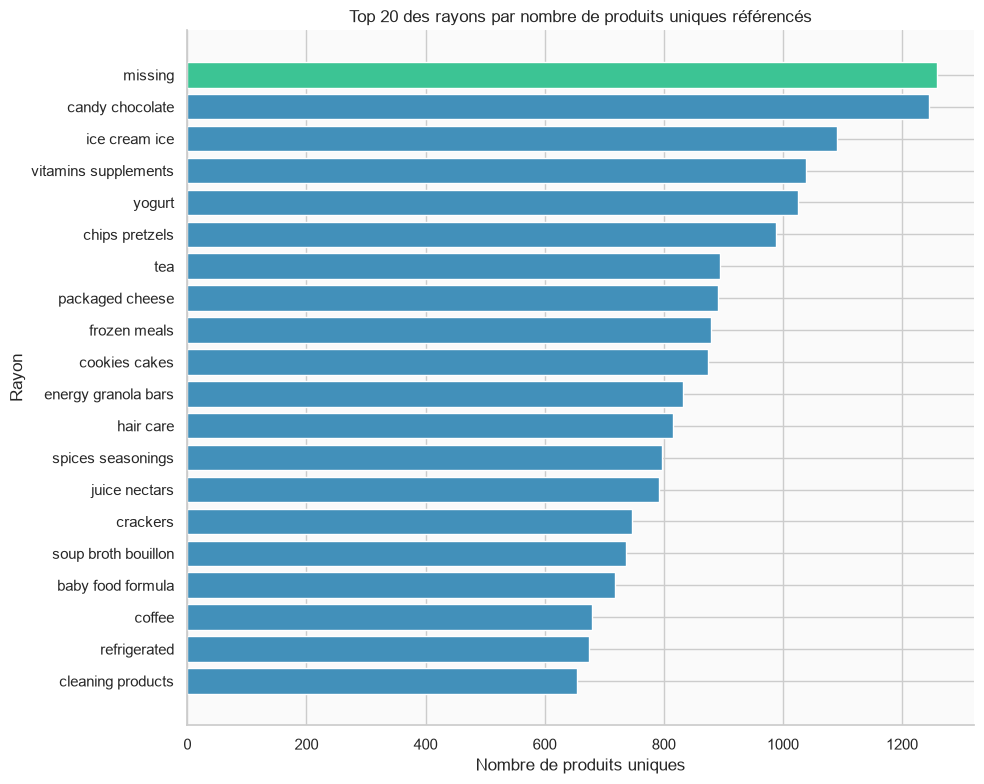

In [12]:
top_n = 20
top_aisles = products_per_aisle.head(top_n).reset_index()
top_aisles.columns = ["aisle", "product_count"]

colors = [COLORS["accent"] if aisle in ["missing", "other"] else COLORS["typique"] for aisle in top_aisles["aisle"]]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top_aisles["aisle"][::-1], top_aisles["product_count"][::-1], color=colors[::-1])
ax.set_xlabel("Nombre de produits uniques")
ax.set_ylabel("Rayon")
ax.set_title(f"Top {top_n} des rayons par nombre de produits uniques référencés")

plt.tight_layout()
plt.show()

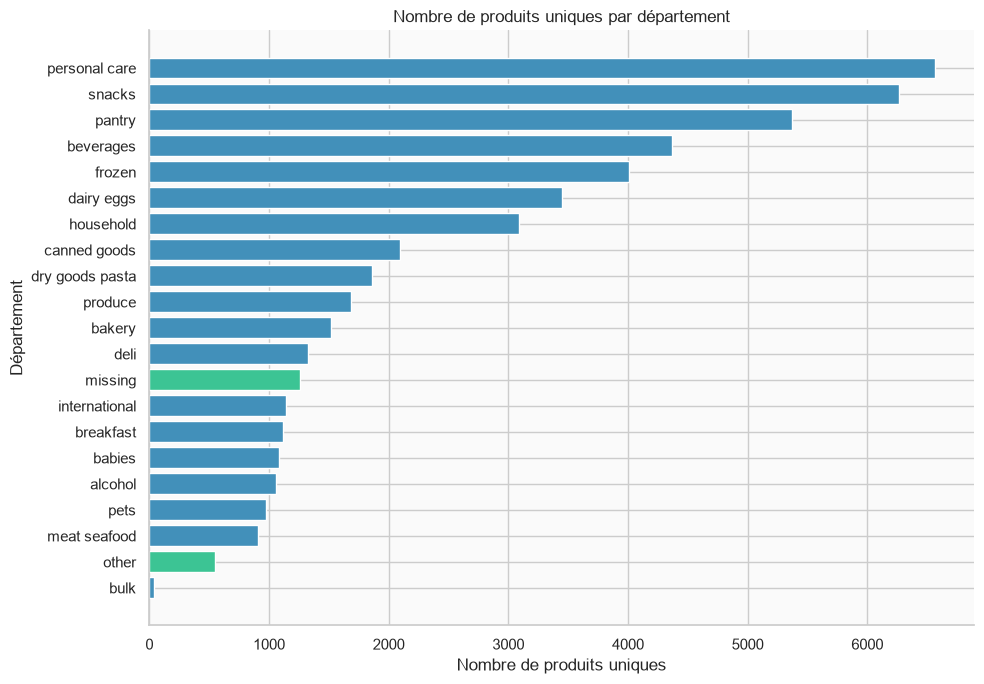

In [13]:
products_per_dept = products_full.groupby("department")["product_id"].nunique().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
colors_dept = [COLORS["accent"] if dept in ["missing", "other"] else COLORS["typique"] for dept in products_per_dept.index]
ax.barh(products_per_dept.index[::-1], products_per_dept.values[::-1], color=colors_dept[::-1])
ax.set_xlabel("Nombre de produits uniques")
ax.set_ylabel("Département")
ax.set_title("Nombre de produits uniques par département")

plt.tight_layout()
plt.show()

**Réponse à la question :** 
le nombre de produits uniques référencés varie fortement d'un rayon et d'un département à l'autre. Au niveau département, "personal care" (17 rayons), "snacks", "pantry" et "beverages" sont les plus fournis en diversité de rayons, tandis que des départements comme "pets", "meat seafood" ou "deli" n'en comptent que 2 à 5.

Au niveau rayon, "candy chocolate" (1246 produits) domine largement, suivi de "vitamins supplements" (1038) et "hair care" (816) contre certains rayons très restreints comme "meat seafood" ou "pets", qui n'affichent que quelques dizaines de produits.

**Implication business :** 
Cette forte disparité soulève la question de savoir si elle reflète une vraie différence de demande client, ou si certains rayons sont structurellement sous-fournis par rapport à leur potentiel de vente. 
C'est précisément ce que la question suivante (diversité de produits vs volume de commandes) va permettre de vérifier.

## Question 2 : Diversité de produits et volume de commandes

**Question :** 
Y a-t-il un lien entre la diversité de produits d'un rayon et son volume de commandes ?

**Hypothèse à tester :** 
Il existe une corrélation entre la diversité de produits référencés dans un rayon et son volume de commandes.

### Pourquoi exclure "missing" et "other" de ce calcul

Une corrélation mesure si deux variables suivent une même logique d'évolution. "missing" et "other" regroupent des produits sans lien thématique cohérent (contrairement aux vrais rayons), et leur inclusion risquerait de fausser le coefficient de corrélation — en particulier parce que "missing" (1258 produits) est un point extrême qui pourrait influencer le résultat de façon disproportionnée. Ces catégories restent néanmoins visibles ailleurs dans l'analyse, elles ne sont 
exclues que localement pour ce test statistique précis.

On construit deux mesures par rayon : la diversité de produits 
(catalogue) et le volume de commandes (comportement d'achat réel).

In [14]:
diversity_per_aisle = products_full[products_full["aisle"] != "other"]
diversity_per_aisle = diversity_per_aisle[diversity_per_aisle["aisle"] != "missing"]
diversity_per_aisle = diversity_per_aisle.groupby("aisle")["product_id"].nunique()
diversity_per_aisle.name = "product_diversity"

volume_per_aisle = data[~data["aisle"].isin(["missing", "other"])]
volume_per_aisle = volume_per_aisle.groupby("aisle")["product_id"].count()
volume_per_aisle.name = "order_volume"

aisle_stats = pd.concat([diversity_per_aisle, volume_per_aisle], axis=1).reset_index()
aisle_stats.head()

,aisle,product_diversity,order_volume
0,air fresheners candles,355,6529
1,asian foods,605,55247
2,baby accessories,44,2672
3,baby bath body care,132,2802
4,baby food formula,718,127449


Pour tester notre hypothèse, on utilise `scipy.stats`, la librairie de référence en Python pour les calculs statistiques (tests d'hypothèses, distributions de probabilité, corrélations...). On calcule ici le coefficient de corrélation de Pearson entre nos deux variables.

In [15]:
correlation, p_value = pearsonr(aisle_stats["product_diversity"], aisle_stats["order_volume"])
print(f"Coefficient de corrélation de Pearson : {correlation:.3f}")
print(f"P-value : {p_value:.5f}")

Coefficient de corrélation de Pearson : 0.299
P-value : 0.00051


**Résultat du test statistique :**
- Coefficient de corrélation de Pearson : 0,299 
(Correspond à un chiffre entre -1 et +1 qui mesure à quel point deux variables évoluent ensemble, plus il est proche de 1 plus le lien est fort)
- P-value : 0,00051 (< 0,05, donc statistiquement significatif autrement dit, il y a moins de 0,1% de chances que cette corrélation soit due au hasard)

**Interprétation :** 
Il existe bien une corrélation positive entre la diversité de produits d'un rayon et son volume de commandes, et cette relation est statistiquement significative (peu probable qu'elle soit due au hasard). 
Cependant, la force de cette corrélation reste faible à modérée (0,299 sur une échelle de -1 à +1, où 0 signifierait aucun lien et 1 un lien 
parfait) : la diversité de produits n'explique qu'une partie limitée 
des écarts de volume entre rayons. 
D'autres facteurs (prix, habitudes d'achat, fréquence de consommation 
du type de produit) jouent probablement un rôle au moins aussi 
important.

Le nuage de points ci-dessous permet de visualiser cette relation.

In [16]:
fig = px.scatter(
    aisle_stats,
    x="product_diversity",
    y="order_volume",
    hover_name="aisle",
    title="Diversité de produits vs volume de commandes, par rayon",
    labels={"product_diversity": "Nombre de produits uniques", "order_volume": "Volume de commandes"},
    trendline="ols",
)
fig.show()

**Note technique :** 
Comme pour la question précédente, le graphique interactif ci-dessus s'affiche pleinement dans l'export HTML, tandis que la version statique ci-dessous garantit un rendu fiable sur GitHub.

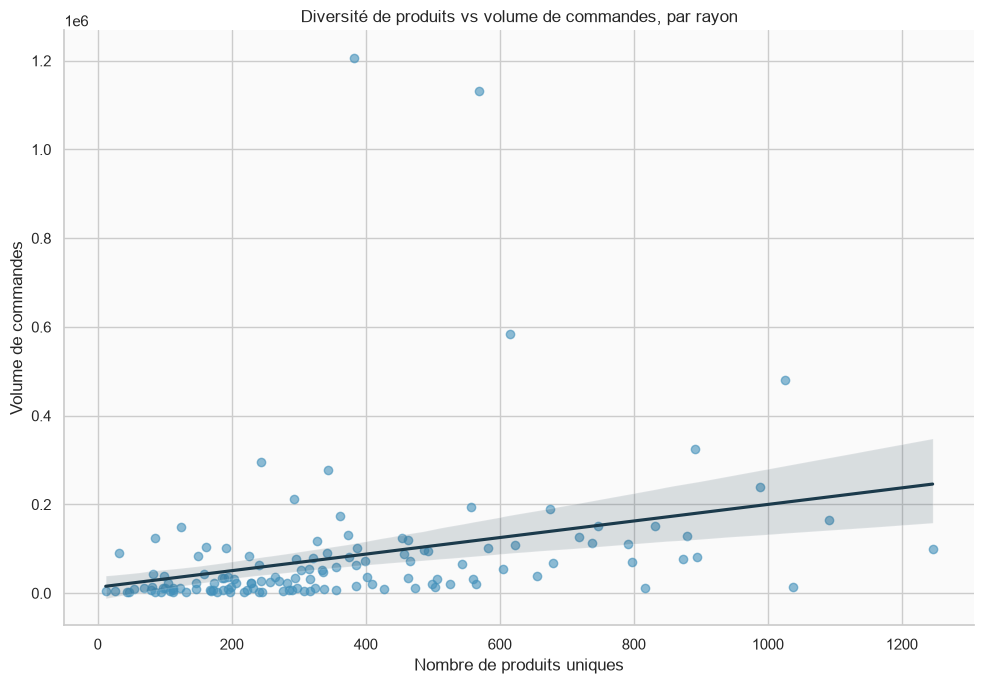

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.regplot(
    data=aisle_stats,
    x="product_diversity",
    y="order_volume",
    scatter_kws={"alpha": 0.6, "color": COLORS["typique"]},
    line_kws={"color": COLORS["fidèle"]},
    ax=ax
)
ax.set_xlabel("Nombre de produits uniques")
ax.set_ylabel("Volume de commandes")
ax.set_title("Diversité de produits vs volume de commandes, par rayon")

plt.tight_layout()
plt.show()

Le nuage de points confirme visuellement la corrélation faible mesurée, la tendance générale est positive (ligne de tendance croissante), mais la majorité des rayons se concentrent avec un volume de commandes modéré, quelle que soit leur diversité.

Trois rayons se démarquent nettement avec un volume de commandes très supérieur au reste : **fresh fruits** (382 produits, plus d'1,2 million de commandes), **fresh vegetables** (569 produits, plus d'1,1 million de commandes), et **packaged vegetables fruits** (615 produits, environ 585 000 commandes). Ces rayons de produits frais, à consommation quotidienne et récurrente, génèrent un volume de commandes très élevé malgré une diversité de produits pourtant modérée, ce qui explique en partie la faiblesse de la corrélation globale.

**Conclusion :** 
La diversité de produits joue un rôle réel mais limité dans le volume de commandes d'un rayon. D'autres facteurs, comme la fréquence de consommation naturelle du type de produit (produits essentiels vs produits occasionnels), semblent avoir un poids au moins aussi important.

## Question 3 : Diversité de panier et segment client

**Question :** 
Dans un panier, combien de produits de différents départements/rayons peut-on trouver, et cette diversité diffère-t-elle selon le segment client ?

**Hypothèse à tester :** 
On suppose qu'un client plus fidèle (ayant commandé plus fréquemment) a statistiquement plus d'occasions d'explorer le site, et pourrait donc présenter une diversité de panier plus élevée que les clients occasionnels.

**Précision méthodologique :** 
L'analyse mesure la diversité d'un panier donné(une commande individuelle) pas la diversité cumulée sur l'ensemble de l'historique d'achat d'un client. 

In [18]:
orders_diversity = data.drop_duplicates(subset="order_id")[["order_id", "dept_per_order", "customer_segment"]]
diversity_by_segment = orders_diversity.groupby("customer_segment", observed=True)["dept_per_order"].describe()
diversity_by_segment

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
occasionnel,141236.0,4.676187,2.594878,1.0,3.0,4.0,6.0,17.0
typique,325665.0,4.783772,2.594522,1.0,3.0,4.0,6.0,17.0
fidèle,597788.0,4.721697,2.511192,1.0,3.0,4.0,6.0,17.0


On regarde maintenant au niveau rayon, plus granulaire :

In [19]:
orders_diversity_aisle = data.drop_duplicates(subset="order_id")[["order_id", "aisles_per_order", "customer_segment"]]
diversity_by_segment_aisle = orders_diversity_aisle.groupby("customer_segment", observed=True)["aisles_per_order"].describe()
diversity_by_segment_aisle

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
occasionnel,141236.0,7.082500,4.774840,1.0,3.0,6.0,10.0,42.0
typique,325665.0,7.303742,4.832166,1.0,4.0,6.0,10.0,47.0
fidèle,597788.0,7.272013,4.707685,1.0,4.0,6.0,10.0,51.0


In [20]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Diversité par département", "Diversité par rayon"))

for segment in ["occasionnel", "typique", "fidèle"]:
    fig.add_trace(
        go.Box(y=orders_diversity[orders_diversity["customer_segment"] == segment]["dept_per_order"], name=segment, boxpoints=False),
        row=1, col=1
    )

for segment in ["occasionnel", "typique", "fidèle"]:
    fig.add_trace(
        go.Box(y=orders_diversity_aisle[orders_diversity_aisle["customer_segment"] == segment]["aisles_per_order"], name=segment, showlegend=False, boxpoints=False),
        row=1, col=2
    )

fig.update_yaxes(title_text="Nombre de départements", row=1, col=1)
fig.update_yaxes(title_text="Nombre de rayons", row=1, col=2)

fig.update_layout(title="Diversité du panier par segment client", showlegend=False, height=500)
fig.show()

**Note technique :** comme pour la question précédente, le graphique interactif (Plotly) ci-dessus s'affiche pleinement dans l'export HTML du notebook, tandis que la version statique ci-dessous garantit un rendu fiable.

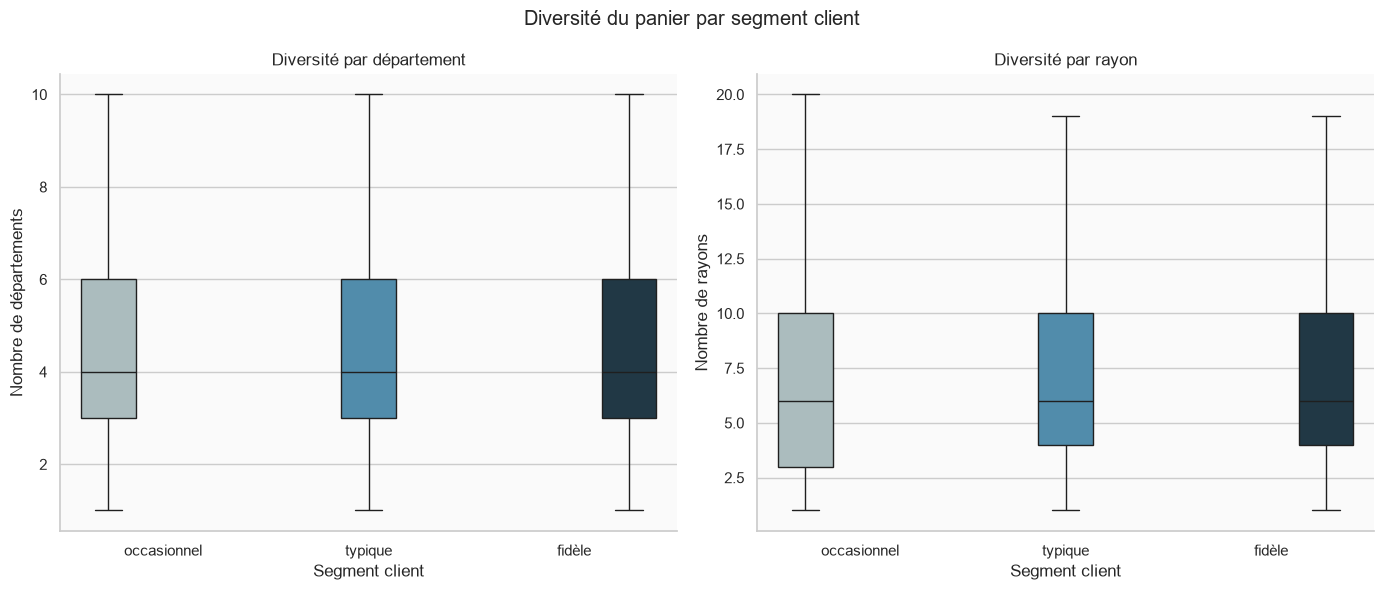

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(
    data=orders_diversity,
    x="customer_segment",
    y="dept_per_order",
    hue="customer_segment",
    palette=PAL_SEGMENTS,
    legend=False,
    showfliers=False,
    ax=axes[0]
)
axes[0].set_xlabel("Segment client")
axes[0].set_ylabel("Nombre de départements")
axes[0].set_title("Diversité par département")

sns.boxplot(
    data=orders_diversity_aisle,
    x="customer_segment",
    y="aisles_per_order",
    hue="customer_segment",
    palette=PAL_SEGMENTS,
    legend=False,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_xlabel("Segment client")
axes[1].set_ylabel("Nombre de rayons")
axes[1].set_title("Diversité par rayon")

fig.suptitle("Diversité du panier par segment client")
plt.tight_layout()
plt.show()

### Conclusion

**Résultat :** 
L'observation descriptive ne va pas dans le sens de l'hypothèse initiale. La diversité d'un panier donné (en départements comme en rayons) est quasiment identique entre les 3 segments clients, tant l'écart entre les moyennes est faible.

Le box plot confirme visuellement cette similarité, les 3 boîtes se superposent presque parfaitement sur les deux niveaux de granularité. Seuls les maximums extrêmes (valeurs aberrantes, non représentées sur les graphiques par souci de lisibilité) augmentent légèrement avec la fidélité, un effet mécanique lié au plus grand nombre de commandes des clients fidèles, pas à un vrai changement de comportement d'achat.

**Interprétation :** 
Etre un client fidèle n'amène pas naturellement à varier davantage ses achats au sein d'un panier donné. La fidélité et la diversité d'achat semblent être deux dimensions indépendantes du comportement client.

**Implication business :** 
On ne peut pas compter sur la fidélisation seule pour élargir les habitudes d'achat des clients vers plus de rayons/départements. Des actions ciblées seraient nécessaires, par exemple des recommandations croisées entre rayons, des promotions découverte, ou une mise en avant de produits de départements peu visités par ce client en particulier.

## Conclusion générale — Rayon/Département

Cette section visait à répondre à une question business centrale : **l'organisation du catalogue en ligne (répartition des produits par rayon/département) influence-t-elle les commandes, et faut-il mettre certains rayons en avant ?**

Les trois analyses menées convergent vers un même constat : la diversité de produits, bien qu'elle joue un rôle, n'est pas le levier principal du succès d'un rayon ou de l'exploration d'achat d'un client.

- La quantité de produits référencés varie fortement d'un rayon à l'autre (Q1), mais un large assortiment ne garantit pas mécaniquement un volume de ventes élevé : la corrélation mesurée reste faible (0,299), et certains rayons à forte rotation (produits du quotidien comme les fruits/légumes frais) génèrent un volume très élevé malgré une diversité modérée (Q2).

- La fidélisation d'un client (mesurée par son volume de commandes) n'entraîne pas naturellement une exploration plus large du magasin en ligne : un client fidèle garde le même profil de diversité de panier qu'un client occasionnel (Q3).

**Recommandation :** 
Plutôt que d'élargir uniformément l'assortiment de tous les rayons en espérant un gain de ventes automatique, le site gagnerait à identifier spécifiquement les rayons à fort potentiel de rotation (produits de consommation courante) et à concentrer les efforts de mise en avant sur ceux-ci. En parallèle, des actions ciblées (recommandations croisées, promotions découverte) seraient nécessaires pour encourager activement les clients fidèles comme occasionnels à diversifier leurs achats, plutôt que de compter sur un effet naturel de la fidélisation.

# III. Evolution du comportement d'achat

**Objectif**: Comprendre comment le comportement d'achat varie selon le profil du client (occasionnel, typique, fidèle) et identifier les produits qui génèrent de la récurrence.

**Questions à traiter**:

1. Comment évoluent les quantités d'achat selon le segment client ?
2. Quel est le taux de réachat global et par segment ?
3. Quels sont les produits les plus rachetés ?

**Impact business attendu**:
Identifier à quel moment les clients deviennent fidèles pour concentrer les actions de rétention sur les commandes critiques.

## Vérification rapide de la segmentation

Avant d'analyser, on vérifie que les 3 segments sont bien répartis et cohérents avec les quartiles observés dans le notebook 01.

### Distribution des utilisateurs par segment

In [26]:
users = data.groupby("user_id").agg(
    segment=("customer_segment", "first"),
    total_orders=("user_total_orders", "first")
).reset_index()

print("Répartition des utilisateurs par segment :")
print(users["segment"].value_counts().sort_index())
print(f"\nTotal : {len(users):,} utilisateurs")

Répartition des utilisateurs par segment :
segment
occasionnel    76224
typique        70769
fidèle         42987
Name: count, dtype: int64

Total : 189,980 utilisateurs


## 1- Comment évoluent les quantités d'achat selon le segment client ?

On cherche à savoir si les clients fidèles commandent plus d'articles par commandes que les occasionnels, et si la taille du panier évolue au fil des commandes.

L'objectif serait de mettre en place des cartes de fidélité afin de récompenser la fidélité de la clientèle, mais inciterait également à acheter plus.

In [27]:
orders_level = data.groupby(["order_id", "customer_segment", "order_number"]).agg(
    cart_size =("product_id", "count")
).reset_index()

orders_level.groupby("customer_segment")["cart_size"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
occasionnel,141236.0,9.7,7.4,1.0,4.0,8.0,13.0,100.0
typique,325665.0,10.0,7.5,1.0,5.0,8.0,14.0,127.0
fidèle,597788.0,10.2,7.5,1.0,5.0,8.0,14.0,137.0


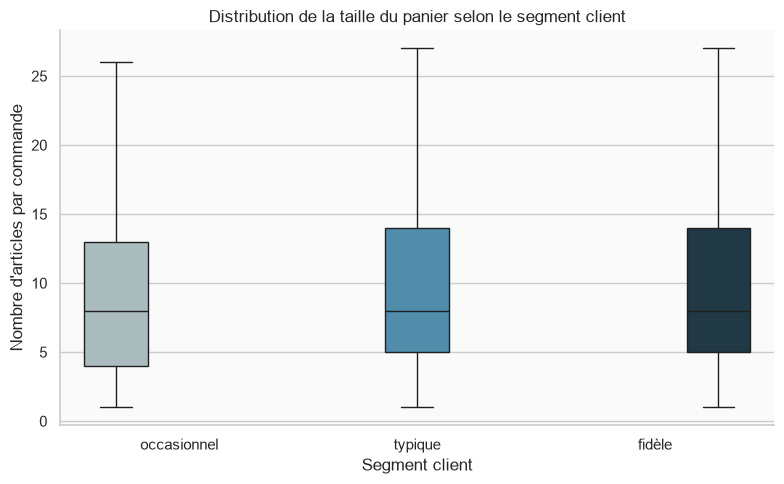

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=orders_level,
    x="customer_segment",
    y="cart_size",
    hue="customer_segment",
    palette=PAL_SEGMENTS,
    legend=False,
    showfliers=False,
    ax=ax
)

ax.set_xlabel("Segment client")
ax.set_ylabel("Nombre d'articles par commande")
ax.set_title("Distribution de la taille du panier selon le segment client")

plt.tight_layout()
plt.show()

### Interprétation

D'après les calculs, les trois segments présentent un comportement d'achat homogène en termes de taille de panier.

La médiane est identique, 8 articles, quel que soit le segment. L'écart entre occasionnels et fidèles n'est que de **+0.5 article en moyenne**, soit une différence de ~5 %, mais négligeable en pratique.

On peut déduire que la fidélité se traduit par une fréquence de commande plus élevée, et non par des paniers plus gros.
Un client fidèle ne remplit pas plus son panier, mais il revient simplement plus souvent.

### Implication business : 

Un programme de fidélité classique (carte à points sur le montant) aurait un impact limité puisque la taille du panier est stable. Il serait plus pertinent de **récompenser la fréquence** plutôt que le volume par commande.

Le boxplot ci-dessus rend cette homogénéité visible : les trois distributions se superposent presque parfaitement, ce qui renforce visuellement le constat que la fidélité n'augmente pas la taille du panier.

## 2- Quel est le taux de réachat global et par segment client ?

La colonne reordered vaut 1 si le client a déjà commandé "ce produit avant", sinon 0. Un taux élevé signifie que les clients rachètent les mêmes produits, signe d'habitudes et de fidélité produit.

In [ ]:
global_reorder = data["reordered"].mean()
print(f"Taux de réachat moyen: {global_reorder:.1%}")

reorder_by_segment = (
    data.groupby("customer_segment", observed=True)["reordered"]
    .mean()
    .reset_index()
    .rename(columns={"reordered": "taux_reachat"})
)
reorder_by_segment["taux_reachat_pct"] = (reorder_by_segment["taux_reachat"] * 100).round(1)
reorder_by_segment

Taux de réachat moyen: 59.0%


,customer_segment,taux_reachat,taux_reachat_pct
0,occasionnel,0.301364,30.1
1,typique,0.509241,50.9
2,fidèle,0.697887,69.8


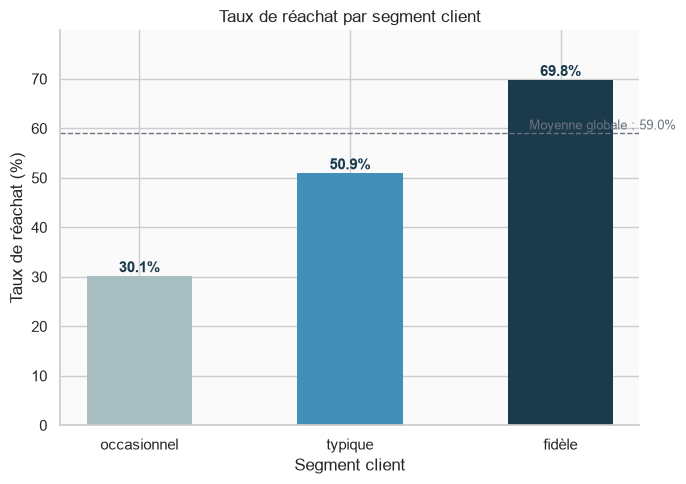

In [30]:
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    reorder_by_segment["customer_segment"].astype(str),
    reorder_by_segment["taux_reachat"] * 100,
    color=PAL_SEGMENTS,
    edgecolor="none",
    width=0.5
)

ax.axhline(y=global_reorder * 100, color=COLORS["grey"], linestyle="--", linewidth=1)
ax.text(
    2.55, global_reorder * 100 + 0.8,
    f"Moyenne globale : {global_reorder:.1%}",
    color=COLORS["grey"], fontsize=9, ha="right"
)

for bar, val in zip(bars, reorder_by_segment["taux_reachat_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
        f"{val}%", ha="center", fontsize=11, fontweight="bold", color=COLORS["fidèle"]
    )

ax.set_xlabel("Segment client")
ax.set_ylabel("Taux de réachat (%)")
ax.set_title("Taux de réachat par segment client")
ax.set_ylim(0, max(reorder_by_segment["taux_reachat"] * 100) + 10)

plt.tight_layout()
plt.show()

### Interprétation:

Le taux de réachat varie entre segment, avec une moyenne de 59% de taux de réachat.
Les clients occasionnels ont un taux de réachat de 28.2% (bien en dessous de la moyenne)
Les clients typiques ont un taux de réachat se rapprochant de la moyenne, soit 48,6%.
Et les client fidèles ont un taux de réachat supérieur à la moyenne, soit 69,2 %.

Nous avons constaté précédemment que la taille du panier était quasi identique entre segments (~8 articles). Le taux de réachat révèle une différence significative : un client fidèle rachète 7 produits sur 10 qu'il a déjà commandés, contre moins de 3 sur 10 chez un occasionnel.

Cela confirme le constat précédent: la fidélité se traduit par la récurrence, et non par le volume.

### Implication business

Nous pouvons émettre 3 hypothèses concernant cette analyse:

- **Hypothèse 1: Produits ancres** : certains produits à fort taux de réachat "verrouillent" le client sur la plateforme (produits du quotidien indispensables).
- **Hypothèse 2: Satisfaction et fidélisation** : le client revient par habitude ou satisfaction globale du service, indépendamment des produits spécifiques.
- **Hypothèse 3: Effet d'habitude de commande** : les clients fidèles utilisent la fonction "recommander" ou reconstituent un panier type par automatisme, ce qui gonfle mécaniquement le taux de réachat.

## 3- Quels sont les produits les plus rachetés ?

On identifie les produits ayant le plus de récurrence d'achat: ceux que les clients rachètent commande après commande.

In [ ]:
top_reordered = (
    data[data["reordered"] == 1]
    .groupby("product_name")
    .size()
    .nlargest(20)
    .reset_index(name="nb_reorders")
)
top_reordered

# IV. Temporalité

**Objectif** : 
Comprendre les habitudes temporelles de commande des clients (moment de la semaine et de la journée), afin d'identifier les périodes de forte affluence et les comportements de commandes répétées sur une même journée.

**Questions à traiter** :

1. Quand est-ce que les clients commandent le plus (heatmap jour × heure) ?
2. Les clients commandent-ils parfois plusieurs fois le même jour, et dans quelle proportion ?

**Impact business attendu** : 
Identifier les pics d'activité pour optimiser les ressources (stocks, personnel, capacité de livraison) aux moments clés, et détecter des comportements de commandes fractionnées pouvant révéler des frictions dans l'expérience d'achat.

## 1. Quand est-ce que les clients commandent le plus (heatmap jour × heure) ?

On mesure ici le nombre de **commandes passées** (pas de produits achetés) par jour de la semaine et heure de la journée. Comme `data` contient une ligne par produit dans une commande, on déduplique d'abord par `order_id` pour ne compter chaque commande qu'une seule fois, quelle que soit la taille de son panier. On réutilise la colonne `day_name`, déjà construite par `enrich_dataframe()`.

In [22]:
orders_time = data.drop_duplicates(subset="order_id")[["order_id", "day_name", "order_hour_of_day"]]
heatmap_data = orders_time.groupby(["day_name", "order_hour_of_day"], observed=True).size().unstack(fill_value=0)

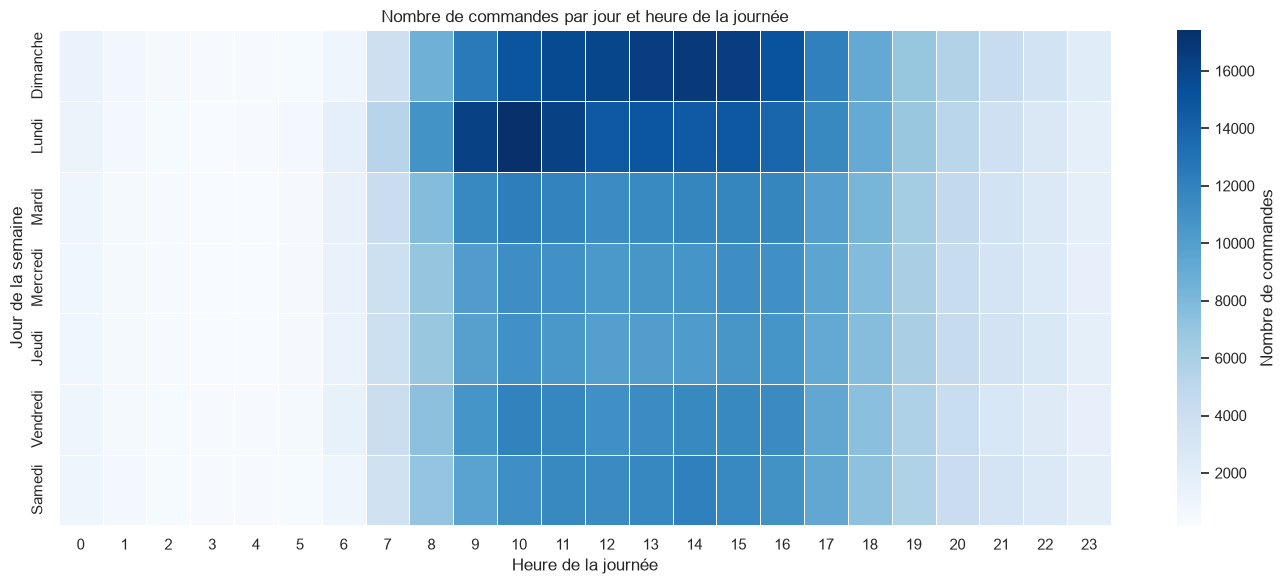

In [23]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    heatmap_data,
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Nombre de commandes"},
    ax=ax
)
ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Jour de la semaine")
ax.set_title("Nombre de commandes par jour et heure de la journée")
plt.tight_layout()
plt.show()

**Réponse à la question :** 
Les commandes se concentrent nettement le week-end et en début de semaine, en particulier le **dimanche** et le **lundi**, avec un pic entre 9h et 16h environ. À l'inverse, les jours 
du milieu de semaine (mardi à vendredi) affichent une activité plus homogène et globalement plus faible. Les horaires de nuit (0h-6h) restent très peu actifs, tous les jours confondus.

**Implication business :** 
Ces créneaux de forte affluence (dimanche/lundi, milieu de journée) sont les moments à prioriser pour la disponibilité des stocks, la capacité de livraison, et le support 
client. À l'inverse, les heures creuses (nuit) pourraient être utilisées pour la maintenance technique ou les mises à jour de l'infrastructure sans impacter l'expérience utilisateur.

## 2. Les clients commandent-ils parfois plusieurs fois le même jour, et dans quelle proportion ?

La colonne `days_since_prior_order` indique le nombre de jours écoulés depuis la commande précédente du même utilisateur. Une valeur de 0 signifie que la commande précédente a eu lieu le même jour. On calcule cette proportion au niveau commande, en dédupliquant par `order_id`, et on la compare selon le segment client.

In [24]:
same_day_by_segment = data.drop_duplicates(subset="order_id")[["order_id", "days_since_prior_order", "customer_segment"]]
same_day_by_segment["same_day"] = same_day_by_segment["days_since_prior_order"] == 0

same_day_count = same_day_by_segment["same_day"].sum()
total_orders = same_day_by_segment.shape[0]
same_day_pct = same_day_count / total_orders * 100

same_day_rate_by_segment = same_day_by_segment.groupby("customer_segment", observed=True)["same_day"].mean() * 100

print(f"Commandes le même jour que la précédente : {same_day_count:,} sur {total_orders:,} ({same_day_pct:.2f}%)")

Commandes le même jour que la précédente : 21,245 sur 1,064,689 (2.00%)


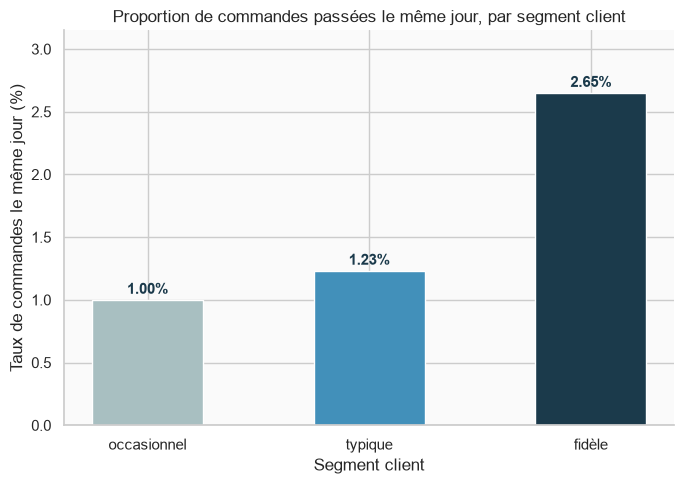

In [25]:
fig, ax = plt.subplots(figsize=(7, 5))
segments = same_day_rate_by_segment.index.tolist()
values = same_day_rate_by_segment.values
colors_bar = [COLORS[s] for s in segments]

bars = ax.bar(segments, values, color=colors_bar, width=0.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f"{val:.2f}%", ha="center", fontsize=11, fontweight="bold", color=COLORS["fidèle"])

ax.set_xlabel("Segment client")
ax.set_ylabel("Taux de commandes le même jour (%)")
ax.set_title("Proportion de commandes passées le même jour, par segment client")
ax.set_ylim(0, max(values) + 0.5)
plt.tight_layout()
plt.show()

**Résultat :** 
2,00% des commandes sont passées le même jour que la commande précédente de l'utilisateur (21 245 commandes sur 1 064 689). 
Ce taux varie selon le segment client :

Segment - Taux de commandes le même jour
Occasionnel - 1,00% 
Typique - 1,23%
Fidèle - 2,65% 

**Interprétation :** 
Les clients fidèles sont environ 2,6 fois plus susceptibles de recommander le même jour que les clients occasionnels. 
Cet écart peut s'expliquer en partie par un effet mécanique (plus de commandes au total = plus d'occasions statistiques de tomber sur ce cas de figure), mais pourrait aussi révéler un vrai comportement : des clients qui complètent une commande oubliée, ou qui fractionnent volontairement leurs achats en plusieurs commandes rapprochées.

**Implication business :** 
Ce phénomène, bien que minoritaire, pourrait signaler des frictions dans l'expérience de commande (produit oublié, besoin urgent après coup) plutôt qu'un choix délibéré. Plutôt que de faciliter une seconde commande, il serait pertinent de proposer une fenêtre de modification (par exemple 15 minutes après validation) permettant au client d'ajouter un produit oublié directement à sa commande initiale. 
Cela répondrait à la cause probable du phénomène tout en évitant des frais de livraison et de traitement dupliqués, aussi bien pour le client que pour la plateforme.

## Conclusion générale — Temporalité

Les deux analyses montrent deux choses complémentaires. D'abord, on peut prévoir globalement quand les commandes arrivent : surtout le dimanche et le lundi, en journée (Q1). Ensuite, on voit que ce rythme n'est pas exactement le même pour tout le monde : les clients fidèles recommandent plus souvent le même jour que les occasionnels, souvent par oubli d'un produit (Q2).

**Recommandation :** 
La plateforme peut planifier ses stocks et sa capacité de livraison à l'avance en se basant sur les créneaux identifiés. Pour réduire les commandes multiples liées à un oubli, une 
fenêtre de modification après validation (voir Q2) serait une piste concrète à explorer.